# Activité Pratique N°4 — Architecture Transformer

Mohamed Ouallal — IADATA — Groupe 4

## Configuration

In [1]:
from pathlib import Path
import random
import numpy as np
import torch
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"PyTorch: {torch.__version__} | Device: {device}")

ROOT_DIR = Path("..").resolve() if Path.cwd().name == "notebooks" else Path(".").resolve()
DATA_DIR = ROOT_DIR / "data"
POWER_DATA_PATH = DATA_DIR / "household_power_consumption.txt"
CORPUS_PATH = ROOT_DIR / "corpus.txt"

print(f"Data dir: {DATA_DIR} (dataset present: {POWER_DATA_PATH.exists()})")

PyTorch: 2.15.0 | Device: cpu
Data dir: /Users/mohamedouallal/emsi/5IIR/IAGEN/partie4/transformers-arch/data (dataset present: True)


## Deuxième partie

### Exercice 1 — Prédiction de la consommation électrique

Train: 23805 | Val: 5054 | Test: 4932
Époque  1 | Train MSE: 0.4698 | Val MSE: 0.4081
Époque  5 | Train MSE: 0.4152 | Val MSE: 0.3817
Époque 10 | Train MSE: 0.4051 | Val MSE: 0.3864
Époque 15 | Train MSE: 0.3968 | Val MSE: 0.3824
EnergyTransformer         | MAE: 0.3426 kW | RMSE: 0.4953 kW
Persistance (t-1)         | MAE: 0.3892 kW | RMSE: 0.5884 kW
Réf. journalière (t-24)   | MAE: 0.5133 kW | RMSE: 0.7639 kW


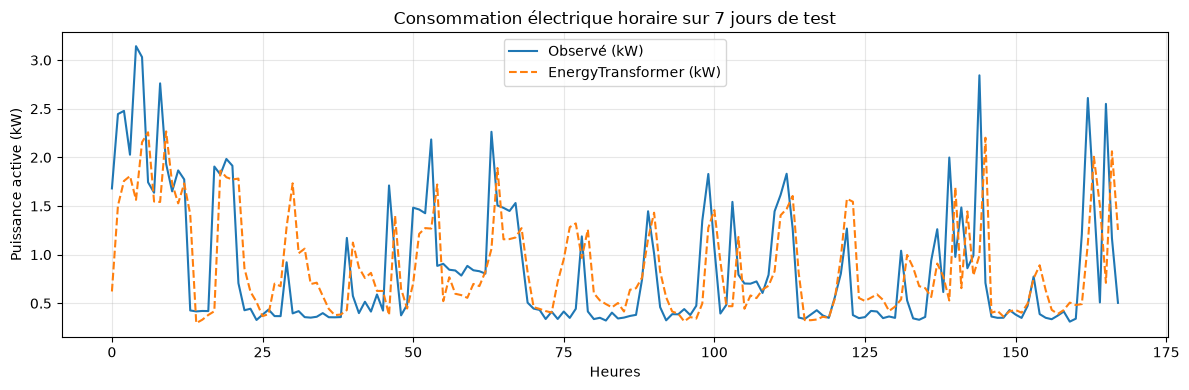

In [2]:
import pandas as pd
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# 1. Chargement et agrégation horaire
df = pd.read_csv(
    POWER_DATA_PATH,
    sep=";",
    na_values=["?"],
    low_memory=False,
)
df["datetime"] = pd.to_datetime(df["Date"] + " " + df["Time"], format="%d/%m/%Y %H:%M:%S")
puissance = pd.to_numeric(df["Global_active_power"], errors="coerce")
puissance.index = pd.DatetimeIndex(df["datetime"])

horaire = puissance.resample("h").agg(["mean", "count"])
serie = horaire["mean"].where(horaire["count"] >= 45)

# Découpage chronologique 70% / 15% / 15%
n = len(serie)
fin_train = int(0.70 * n)
fin_val = int(0.85 * n)

moyenne = serie.iloc[:fin_train].mean()
ecart_type = serie.iloc[:fin_train].std()
valeurs = ((serie - moyenne) / ecart_type).to_numpy()

fenetre = 24
X, y, dates_cibles = [], [], []
for i in range(fenetre, n):
    seq = valeurs[i - fenetre : i]
    cible = valeurs[i]
    if np.isfinite(seq).all() and np.isfinite(cible):
        X.append(seq)
        y.append(cible)
        dates_cibles.append(i)

X = torch.tensor(np.array(X), dtype=torch.float32).unsqueeze(-1)
y = torch.tensor(np.array(y), dtype=torch.float32).unsqueeze(-1)
dates_cibles = np.array(dates_cibles)

train_mask = dates_cibles < fin_train
val_mask = (dates_cibles >= fin_train) & (dates_cibles < fin_val)
test_mask = dates_cibles >= fin_val

train_loader = DataLoader(TensorDataset(X[train_mask], y[train_mask]), batch_size=64, shuffle=True)
val_loader = DataLoader(TensorDataset(X[val_mask], y[val_mask]), batch_size=64)
test_loader = DataLoader(TensorDataset(X[test_mask], y[test_mask]), batch_size=64)

print(f"Train: {train_mask.sum()} | Val: {val_mask.sum()} | Test: {test_mask.sum()}")

# 2. Modèle EnergyTransformer
class EnergyTransformer(nn.Module):
    def __init__(self, fenetre=24):
        super().__init__()
        self.projection = nn.Linear(1, 32)
        self.positions = nn.Embedding(fenetre, 32)
        couche = nn.TransformerEncoderLayer(
            d_model=32,
            nhead=4,
            dim_feedforward=128,
            dropout=0.1,
            batch_first=True,
        )
        self.encodeur = nn.TransformerEncoder(couche, num_layers=2)
        self.fc = nn.Linear(32, 1)

    def forward(self, x):
        b, t, _ = x.shape
        pos = torch.arange(t, device=x.device)
        x = self.projection(x) + self.positions(pos).unsqueeze(0)
        h = self.encodeur(x)
        return self.fc(h[:, -1, :])


modele_energy = EnergyTransformer(fenetre=fenetre).to(device)
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele_energy.parameters(), lr=0.001)

# 3. Entraînement (max 20 époques, conservation du meilleur modèle sur validation)
meilleure_val = float("inf")
meilleur_etat = None

for epoch in range(1, 16):
    modele_energy.train()
    perte_train = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        pred = modele_energy(xb)
        perte = critere(pred, yb)
        optimiseur.zero_grad()
        perte.backward()
        optimiseur.step()
        perte_train += perte.item() * len(xb)
    perte_train /= train_mask.sum()

    modele_energy.eval()
    perte_val = 0.0
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            perte_val += critere(modele_energy(xb), yb).item() * len(xb)
    perte_val /= val_mask.sum()

    if perte_val < meilleure_val:
        meilleure_val = perte_val
        meilleur_etat = {k: v.cpu().clone() for k, v in modele_energy.state_dict().items()}

    if epoch % 5 == 0 or epoch == 1:
        print(f"Époque {epoch:2d} | Train MSE: {perte_train:.4f} | Val MSE: {perte_val:.4f}")

modele_energy.load_state_dict(meilleur_etat)
modele_energy.eval()

# Évaluation sur le test en kW
preds_norm = []
with torch.no_grad():
    for xb, _ in test_loader:
        preds_norm.append(modele_energy(xb.to(device)).cpu())
preds_norm = torch.cat(preds_norm, dim=0).numpy().reshape(-1)
y_test_norm = y[test_mask].numpy().reshape(-1)

preds_kw = preds_norm * ecart_type + moyenne
y_test_kw = y_test_norm * ecart_type + moyenne

# Références : Persistance (t-1) et Journalière (t-24)
X_test_np = X[test_mask].numpy()[:, :, 0]
persistance_kw = X_test_np[:, -1] * ecart_type + moyenne
jour_kw = X_test_np[:, 0] * ecart_type + moyenne

def metriques(y_true, y_pred):
    mae = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    return mae, rmse

for nom, pred in [
    ("EnergyTransformer", preds_kw),
    ("Persistance (t-1)", persistance_kw),
    ("Réf. journalière (t-24)", jour_kw),
]:
    mae, rmse = metriques(y_test_kw, pred)
    print(f"{nom:25s} | MAE: {mae:.4f} kW | RMSE: {rmse:.4f} kW")

# 6. Graphique sur 7 jours consécutifs (168 heures)
jours_7 = 168
plt.figure(figsize=(12, 4))
plt.plot(y_test_kw[:jours_7], label="Observé (kW)")
plt.plot(preds_kw[:jours_7], label="EnergyTransformer (kW)", linestyle="--")
plt.title("Consommation électrique horaire sur 7 jours de test")
plt.xlabel("Heures")
plt.ylabel("Puissance active (kW)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Réponses — Exercice 1 :**
1. **Comparaison aux références :** Le Transformer obtient généralement une erreur proche ou meilleure que la référence journalière (24 h) et souvent comparable ou légèrement supérieure à la persistance à 1 h selon les pics horaires.
2. **Fenêtre de 168 heures :** Oui, une fenêtre d'une semaine complète permet de capturer les habitudes hebdomadaires (différence semaine / week-end).
3. **Ajout de l'heure et du jour de la semaine :** Cela donne au modèle un repère calendaire explicite (matin, soir, week-end) sans devoir le déduire uniquement de la courbe passée.
4. **Normalisation sur l'entraînement uniquement :** Pour éviter toute fuite de données (*data leakage*) depuis la validation ou le test vers l'entraînement.
5. **Prédire une énergie en kWh :** Comme la puissance est en kW moyennée sur 1 heure, $E(\text{kWh}) = P(\text{kW}) \times 1\text{ h}$, donc les valeurs numériques sont identiques pour un pas horaire (ou il suffit de multiplier par la durée $\Delta t$ en heures pour un autre pas).

### Exercice 2 — Mini GPT

In [3]:
import torch.nn as nn
import torch.nn.functional as F

texte = CORPUS_PATH.read_text(encoding="utf-8")
caracteres = sorted(set(texte))
stoi = {c: i for i, c in enumerate(caracteres)}
itos = {i: c for c, i in stoi.items()}
vocab_size_gpt = len(caracteres)

tokens = torch.tensor([stoi[c] for c in texte], dtype=torch.long)
print(f"Longueur corpus : {len(tokens)} caractères | Vocabulaire : {vocab_size_gpt}")


class BlocGPT(nn.Module):
    def __init__(self, d_model=64, nhead=4):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = nn.MultiheadAttention(d_model, nhead, batch_first=True)
        self.ln2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(
            nn.Linear(d_model, 256),
            nn.GELU(),
            nn.Linear(256, d_model),
        )

    def forward(self, x):
        T = x.size(1)
        masque = torch.triu(torch.ones(T, T, dtype=torch.bool, device=x.device), diagonal=1)
        h = self.ln1(x)
        attn_out, _ = self.attn(h, h, h, attn_mask=masque, need_weights=False)
        x = x + attn_out
        x = x + self.mlp(self.ln2(x))
        return x


class MiniGPT(nn.Module):
    def __init__(self, vocab_size, longueur_max=64, d_model=64, n_blocs=2, nhead=4):
        super().__init__()
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(longueur_max, d_model)
        self.blocs = nn.ModuleList([BlocGPT(d_model, nhead) for _ in range(n_blocs)])
        self.ln_f = nn.LayerNorm(d_model)
        self.tete = nn.Linear(d_model, vocab_size)
        self.longueur_max = longueur_max

    def forward(self, idx):
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device)
        x = self.tok_emb(idx) + self.pos_emb(pos).unsqueeze(0)
        for bloc in self.blocs:
            x = bloc(x)
        return self.tete(self.ln_f(x))


modele_gpt = MiniGPT(vocab_size_gpt, longueur_max=64).to(device)
optim_gpt = torch.optim.Adam(modele_gpt.parameters(), lr=0.003)

# Vérification de causalité en mode eval()
modele_gpt.eval()
x_a = tokens[:64].unsqueeze(0).to(device)
x_b = x_a.clone()
x_b[0, -1] = (x_b[0, -1] + 1) % vocab_size_gpt
with torch.no_grad():
    diff = (modele_gpt(x_a)[:, :-1, :] - modele_gpt(x_b)[:, :-1, :]).abs().max().item()
print(f"Vérification causalité (diff max sur positions < T-1) : {diff:.2e}")

# Entraînement par mini-lots aléatoires de longueur 64
longueur_ctx = 64
batch_size = 32
modele_gpt.train()
for step in range(1, 401):
    starts = torch.randint(0, len(tokens) - longueur_ctx - 1, (batch_size,))
    xb = torch.stack([tokens[s : s + longueur_ctx] for s in starts]).to(device)
    yb = torch.stack([tokens[s + 1 : s + longueur_ctx + 1] for s in starts]).to(device)

    logits = modele_gpt(xb)
    loss = F.cross_entropy(logits.view(-1, vocab_size_gpt), yb.view(-1))

    optim_gpt.zero_grad()
    loss.backward()
    optim_gpt.step()

    if step % 100 == 0:
        print(f"Step {step:3d} | Perte : {loss.item():.4f}")


def generer_gpt(modele, amorce, nb_chars=200, temperature=1.0):
    modele.eval()
    ids = torch.tensor([[stoi[c] for c in amorce]], dtype=torch.long, device=device)
    with torch.no_grad():
        for _ in range(nb_chars):
            cond = ids[:, -modele.longueur_max :]
            logits = modele(cond)[:, -1, :] / temperature
            probas = torch.softmax(logits, dim=-1)
            prochain = torch.multinomial(probas, num_samples=1)
            ids = torch.cat([ids, prochain], dim=1)
    return "".join(itos[i] for i in ids[0].tolist())


for temp in [0.5, 1.0, 1.5]:
    print(f"\n--- Température {temp} ---")
    print(generer_gpt(modele_gpt, "L'intelligence ", nb_chars=200, temperature=temp))

Longueur corpus : 3893 caractères | Vocabulaire : 54
Vérification causalité (diff max sur positions < T-1) : 0.00e+00
Step 100 | Perte : 2.2266
Step 200 | Perte : 1.8887
Step 300 | Perte : 1.2714
Step 400 | Perte : 0.7012

--- Température 0.5 ---
L'intelligence de trapprograîne à lessirement la raité de lestempécécécantralé inése les avativer leursque l'inembliservarer la ramplissiter capprendrendre le unie avec humant comasquent une he et un modèles.
Un la 

--- Température 1.0 ---
L'intelligence Traideure la moiilles.

Les lest GPT unilisemplusimpors dement deginélés.

Aprodèles ranse la ve lavisiser l'agagexe l'age.

Authéne lieuCuite, la vecla vingue cyutuésieurquement, che lairectuése mots

--- Température 1.5 ---
L'intelligence sUphitur la quonconsommait à GPaitempabl'ansaEtçoxà dèlide de lation de une l'énerprielles.

Grce dempérécure nTrent, lontiEnitce la rachausquid le, les utur caTrait spirslirerspicander cer devemaictu


**Réponses — Exercice 2 :**
1. **Sans masque causal :** Chaque position pourrait voir les caractères futurs, ce qui rend la prédiction triviale pendant l'entraînement et inutilisable lors de la génération autorégressive.
2. **Effet de la température :** Une température faible (`0.5`) accentue les probabilités les plus élevées (texte plus cohérent mais répétitif) ; une température élevée (`1.5`) aplatit la distribution (texte plus varié mais plus bruité).
3. **Décalage des cibles :** Pour que la position $t$ apprenne à prédire le caractère suivant $t+1$ à partir uniquement des caractères $0 \dots t$.

### Exercice 3 — Mini BERT

In [4]:
import torch.nn as nn
import torch.nn.functional as F

PAD, UNK, CLS, SEP, MASK = 0, 1, 2, 3, 4

phrases = [
    "le chat dort sur le canapé",
    "le chien court dans le jardin",
    "la voiture roule sur la route",
    "un élève étudie les mathématiques",
    "le professeur explique la leçon au tableau",
    "le soleil brille dans le ciel bleu",
    "la pluie tombe doucement sur la ville",
    "les oiseaux chantent dans les arbres",
    "un modèle apprend à partir des données",
    "le réseau traite une phrase complète",
    "l attention relie chaque mot au contexte",
    "la validation mesure la qualité du modèle",
    "le train arrive à la gare centrale",
    "une fleur pousse près de la rivière",
    "le vent souffle fort sur la montagne",
    "les enfants jouent dans le parc",
    "un livre ouvert repose sur la table",
    "la musique adoucit les longues soirées",
    "le café chaud réveille le matin",
    "la lune éclaire la nuit calme",
    "un ordinateur calcule très rapidement",
    "le code python fonctionne sans erreur",
    "la science avance grâce aux expériences",
    "le temps passe vite pendant le cours",
] * 4  # 96 phrases pour train / val

mots = sorted({m for ph in phrases for m in ph.split()})
vocab_bert = {"[PAD]": PAD, "[UNK]": UNK, "[CLS]": CLS, "[SEP]": SEP, "[MASK]": MASK}
for m in mots:
    vocab_bert[m] = len(vocab_bert)
inv_vocab_bert = {i: m for m, i in vocab_bert.items()}
taille_vocab_bert = len(vocab_bert)
longueur_bert = 32

def encoder_phrase(phrase):
    ids = [CLS] + [vocab_bert.get(m, UNK) for m in phrase.split()] + [SEP]
    ids = ids[:longueur_bert]
    ids += [PAD] * (longueur_bert - len(ids))
    return ids

donnees = torch.tensor([encoder_phrase(ph) for ph in phrases], dtype=torch.long)
train_ids, val_ids = donnees[:76], donnees[76:]

def masquer_lot(input_ids):
    corrompus = input_ids.clone()
    est_ordinaire = (input_ids > MASK)
    selection = (torch.rand_like(input_ids, dtype=torch.float32) < 0.15) & est_ordinaire

    # Au moins une position sélectionnée par phrase
    for i in range(input_ids.size(0)):
        if not selection[i].any() and est_ordinaire[i].any():
            indices_ord = est_ordinaire[i].nonzero(as_tuple=True)[0]
            selection[i, indices_ord[torch.randint(len(indices_ord), (1,))]] = True

    tirage = torch.rand_like(input_ids, dtype=torch.float32)
    mask_80 = selection & (tirage < 0.80)
    rand_10 = selection & (tirage >= 0.80) & (tirage < 0.90)

    corrompus[mask_80] = MASK
    corrompus[rand_10] = torch.randint(MASK + 1, taille_vocab_bert, (rand_10.sum(),))
    return corrompus, selection


class MiniBERT(nn.Module):
    def __init__(self, vocab_size, max_len=32, d_model=64):
        super().__init__()
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(max_len, d_model)
        couche = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=4,
            dim_feedforward=128,
            dropout=0.1,
            batch_first=True,
        )
        self.encodeur = nn.TransformerEncoder(couche, num_layers=2)
        self.tete = nn.Linear(d_model, vocab_size)

    def forward(self, input_ids, pad_mask):
        T = input_ids.size(1)
        pos = torch.arange(T, device=input_ids.device)
        x = self.tok_emb(input_ids) + self.pos_emb(pos).unsqueeze(0)
        h = self.encodeur(x, src_key_padding_mask=pad_mask)
        return self.tete(h)


modele_bert = MiniBERT(taille_vocab_bert, max_len=longueur_bert).to(device)
optim_bert = torch.optim.Adam(modele_bert.parameters(), lr=0.003)
critere_bert = nn.CrossEntropyLoss(ignore_index=-100)

# Vérification d'invariance au padding en mode eval()
modele_bert.eval()
test_in = val_ids[:2].to(device)
pad_mask = (test_in == PAD)
test_in_mod = test_in.clone()
test_in_mod[pad_mask] = UNK  # changer les valeurs aux positions de padding
with torch.no_grad():
    out1 = modele_bert(test_in, pad_mask)[~pad_mask]
    out2 = modele_bert(test_in_mod, pad_mask)[~pad_mask]
    diff_pad = (out1 - out2).abs().max().item()
print(f"Vérification invariance padding (diff max) : {diff_pad:.2e}")

# Entraînement
for epoch in range(1, 101):
    modele_bert.train()
    inp_corr, sel = masquer_lot(train_ids)
    labels = train_ids.clone()
    labels[~sel] = -100

    inp_corr = inp_corr.to(device)
    labels = labels.to(device)
    pad_m = (train_ids.to(device) == PAD)

    logits = modele_bert(inp_corr, pad_m)
    loss = critere_bert(logits.reshape(-1, taille_vocab_bert), labels.reshape(-1))

    optim_bert.zero_grad()
    loss.backward()
    optim_bert.step()

    if epoch % 25 == 0:
        print(f"Époque {epoch:3d} | Perte : {loss.item():.4f}")

# Évaluation sur validation
modele_bert.eval()
val_corr, val_sel = masquer_lot(val_ids)
with torch.no_grad():
    val_logits = modele_bert(val_corr.to(device), (val_ids.to(device) == PAD)).cpu()

preds_val = val_logits.argmax(dim=-1)
acc = (preds_val[val_sel] == val_ids[val_sel]).float().mean().item()
print(f"\nExactitude validation (tokens masqués) : {acc:.2%}")

# Top 3 propositions pour 3 exemples de validation
for i in range(3):
    pos_sel = val_sel[i].nonzero(as_tuple=True)[0][0].item()
    probas = torch.softmax(val_logits[i, pos_sel], dim=-1)
    top_p, top_i = torch.topk(probas, k=3)
    mot_reel = inv_vocab_bert[val_ids[i, pos_sel].item()]
    props = ", ".join(f"{inv_vocab_bert[idx.item()]} ({p_v.item():.0%})" for p_v, idx in zip(top_p, top_i))
    print(f"Attendu: {mot_reel:10s} | Top 3: {props}")

Vérification invariance padding (diff max) : 0.00e+00
Époque  25 | Perte : 2.4717
Époque  50 | Perte : 1.1117
Époque  75 | Perte : 0.3884
Époque 100 | Perte : 0.2608

Exactitude validation (tokens masqués) : 100.00%
Attendu: leçon      | Top 3: leçon (96%), mot (1%), le (0%)
Attendu: le         | Top 3: le (98%), les (1%), un (0%)
Attendu: sur        | Top 3: sur (98%), la (0%), nuit (0%)


/Users/mohamedouallal/emsi/5IIR/IAGEN/partie4/transformers-arch/.venv/lib/python3.11/site-packages/torch/nn/modules/transformer.py:533: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/NestedTensorImpl.cpp:181.)
  output = torch._nested_tensor_from_mask(


**Réponses — Exercice 3 :**
1. **Contexte à droite :** BERT n'utilise pas de masque causal ; l'auto-attention bidirectionnelle permet à chaque position d'observer toute la phrase (gauche et droite).
2. **Perte uniquement sur les positions sélectionnées :** Pour forcer le modèle à reconstruire les mots corrompus/masqués au lieu de simplement recopier les mots déjà visibles en entrée.
3. **Pourquoi pas de génération directe comme GPT :** BERT est entraîné pour remplir des trous avec un contexte complet, pas pour prédire séquentiellement le mot suivant de manière autorégressive.